# 보고서 분석결과 이미지 그림 1~10 재현 노트북

**사용법 (Google Colab)**: 왼쪽 파일 패널에 `교통분석_데이터.zip`을 올리고 위에서부터 차례로 실행합니다. 그림은 `figures/` 폴더에 `fig01~fig10` PNG로 저장됩니다.

| 보고서 그림 | 사용 데이터 | 저장 파일 |
|---|---|---|
| 그림 1 고령화율 vs 종합병원 거리 | 연령별 인구현황, 정류장 승하차(오전 6~9시), 의료기관 시트(종합병원 7곳), 행정동 경계 | fig01 |
| 그림 2 외곽 운행 비중 | 해피콜 운행기록 | fig02 |
| 그림 3 외곽 출발 해피콜 도착 지도 | 해피콜 운행기록, 행정동 경계, 정류장 좌표(Hub), 종합병원 좌표 | fig03 |
| 그림 4 저상노선 후보 7개 | 정류장 좌표·이용량, 행정동 경계, 보고서 7장 노선표 | fig04 |
| 그림 5 Hub 연계 차량점유 | 해피콜 운행기록, Hub 거리(보고서 3장), 핵심 목적지 동 | fig05 |
| 그림 6 동시 운행 특장차 | 해피콜 운행기록(특장차 배차~하차 시각) | fig06 |
| 그림 7 실측 재생 시뮬레이션 | 해피콜 운행기록(특장차 일반 호출), 그림 5 결과 | fig07 |
| 그림 8 외곽 목적지 상위 12 | 해피콜 운행기록, 핵심 목적지 동 | fig08 |
| 그림 9 1건 이동거리 분포 | 해피콜 운행기록 | fig09 |
| 그림 10 차종별 대기·시간대별 취소율 | 해피콜 운행기록(일반 호출 대기, 전체 호출 취소) | fig10 |

## 0. 환경 준비
한글 폰트를 설치하고, zip을 파이썬으로 풀어 한글 파일명이 깨지지 않게 합니다. 그림 공통 스타일과 거리 계산 함수도 정의합니다.

In [1]:
import os, sys, zipfile
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    os.system('pip -q install koreanize-matplotlib geopandas')
if os.path.exists('교통분석_데이터.zip') and not os.path.isdir('교통분석_데이터'):
    zipfile.ZipFile('교통분석_데이터.zip').extractall('.')
DATA = '교통분석_데이터/'
os.makedirs('figures', exist_ok=True)

import heapq
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter
try:
    import koreanize_matplotlib  # Colab 한글 폰트
except ImportError:
    plt.rcParams['font.family'] = 'Noto Sans CJK JP'

# 그림 스타일: 2색 (외곽=주황, 시내·비교=파랑), 회색은 보조
C_OUT, C_IN, C_GRAY = '#eb6834', '#2a78d6', '#b4b2a9'
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e6e5e0'
plt.rcParams.update({
    'axes.unicode_minus': False, 'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': GRID,
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'legend.frameon': False,
})
def save(fig, name):
    fig.savefig(f'figures/{name}.png')
    plt.show()

import re
from matplotlib.patches import Patch
def hav_km(lat1, lon1, lat2, lon2):
    """두 좌표 사이 직선거리(km)"""
    p = np.pi / 180
    a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))
DETOUR = 1.3   # 직선거리 → 도로거리 우회계수

## 공통 데이터 준비
여러 그림이 같이 쓰는 기준을 한 번에 만듭니다.
- 해피콜: 차종 재분류(2025년 G1 특장차·G2 임차택시 / 2026년 G1·G2 특장차 / G3 바우처택시 / G5 자가용), 외곽 12개 읍면 표시, 완료 운행 383,964건, 예약 운행 점유시간 보정
- 공간: 행정동 경계에 정류장·종합병원·읍면 Hub를 연결하고, 주요 정류장 권역 또는 종합병원이 있는 18개 동을 "핵심 목적지 동"으로 정의

In [2]:
hc = pd.read_csv(DATA + 'cheongju_happycall_2025-10_2026-10.csv',
                 dtype={'출발_ADM_CD': str, '목적지_ADM_CD': str}, low_memory=False)
hc['일자'] = pd.to_datetime(hc['일자'])
y26 = hc['일자'] >= '2026-01-01'
hc['차종'] = np.select(
    [hc.차량종류.eq('G1'), hc.차량종류.eq('G2') & y26, hc.차량종류.eq('G2') & ~y26, hc.차량종류.eq('G3'), hc.차량종류.eq('G5')],
    ['특장차', '특장차', '임차택시', '바우처택시', '자가용승용차'], '기타')
hc['특장'] = hc['차종'].eq('특장차')

OUTER12 = ['오창읍', '내수읍', '옥산면', '남이면', '강내면', '미원면', '남일면', '북이면', '문의면', '가덕면', '현도면', '낭성면']
in_cj_o, in_cj_d = hc.출발도시.eq('청주시'), hc.목적지도시.eq('청주시')
hc['o12'] = in_cj_o & hc.출발읍면동.isin(OUTER12)
hc['d12'] = in_cj_d & hc.목적지읍면동.isin(OUTER12)
hc['구간'] = np.select([hc.o12 | hc.d12,
                       hc.출발_읍면동구분.eq('동') & hc.목적지_읍면동구분.eq('동')],
                      ['외곽', '시내'], '기타')

# 예약 운행의 점유·픽업 보정
normal = hc.예약일반.eq('일반')
med_pick = hc[normal].groupby('차종')['픽업소요_분'].median()
hc['픽업'] = np.where(normal, hc['픽업소요_분'], hc['차종'].map(med_pick))
hc['점유'] = np.where(normal, hc['차량점유_분'], hc['탑승시간_분'] + hc['픽업'])
hc['주행km'] = hc['픽업거리_km'] + hc['이동거리_km']

done = hc[hc.운행완료 & ~hc.시간이상치].copy()
print(f'전체 {len(hc):,}건 / 완료(이상치 제외) {len(done):,}건')
print(done.groupby('차종').size().rename('완료 건수').to_frame().T)

전체 443,608건 / 완료(이상치 제외) 383,964건
차종      바우처택시  임차택시  자가용승용차     특장차
완료 건수  195713  8083    4738  175430


In [3]:
# 행정동 경계, 정류장·병원 → 행정동 연결
geo = gpd.read_file(DATA + 'cheongju_grid_100m.geojson')
bnd = geo[geo.ADM_CD.notna()][['ADM_CD', 'ADM_NM', 'geometry']].reset_index(drop=True)
bnd['구분'] = np.where(bnd.ADM_NM.str[-1].isin(['읍', '면']), '읍면', '동')

st = pd.read_csv(DATA + '청주_정류장_월별_시간대별_승하차_.csv', encoding='cp949')
stops = st.groupby(['정류장ID', '정류장명'], as_index=False).agg(위도=('위도', 'first'), 경도=('경도', 'first'))
stops = gpd.sjoin(gpd.GeoDataFrame(stops, geometry=gpd.points_from_xy(stops.경도, stops.위도), crs=4326),
                  bnd[['ADM_NM', 'geometry']], how='left', predicate='within').drop(columns='index_right')

# 보고서 3장의 읍면 Hub(환승 정류장)와 고령자→Hub 도로환산거리(km)
HUB = pd.DataFrame([
    ('오창읍', '오창프라자', 2.1), ('내수읍', '내수삼일아파트', 2.3), ('옥산면', '형제빌라', 1.9),
    ('남이면', '남이면행정복지센터', 4.3), ('강내면', '월곡초등학교', 1.8), ('미원면', '미원우체국', 0.5),
    ('남일면', '고은리', 2.8), ('북이면', '장재', 2.4), ('문의면', '문의초등학교입구', 2.4),
    ('가덕면', '청주운전면허시험장', 3.6), ('현도면', '우록1리', 2.4), ('낭성면', '낭성면행정복지센터', 3.8)],
    columns=['읍면', 'Hub정류장', 'Hub거리_km'])
# 보고서 6장: 현행 노선으로 충북대병원까지 1회 환승이 확인된 읍면
NOW_LINKED = ['가덕면', '낭성면', '문의면', '내수읍', '강내면', '남이면', '오창읍']
HUB['현행노선연결'] = HUB.읍면.isin(NOW_LINKED)
hub_pts = stops[stops.정류장명.isin(HUB.Hub정류장)].drop_duplicates('정류장명')
HUB = HUB.merge(hub_pts[['정류장명', '위도', '경도', 'ADM_NM']].rename(columns={'정류장명': 'Hub정류장', 'ADM_NM': 'Hub소재동'}), on='Hub정류장', how='left')

# 보고서 5장의 주요 정류장 권역 15곳(대표 정류장)
KW = ['도청.그림책정원1937', '시외버스터미널', '사창사거리', '청주대학교.뉴시스', '분평휴먼시아2단지아파트',
      '문화제조창.시청제2임시청사', '사직사거리.시립미술관.교육도서관', '마로니에공원', '산업단지입구',
      '현대3차아파트', '오창프라자', '용암효성아파트', '오송역', '충북대학교병원', '시청신청사예정지']
kw_dong = set(stops[stops.정류장명.isin(KW)].ADM_NM)

hos = pd.read_excel(DATA + '청주_거점병원_의료접근성_분석.xlsx', sheet_name='종합병원_기준점', engine='calamine').dropna(subset=['경도(X)'])
hos = gpd.sjoin(gpd.GeoDataFrame(hos, geometry=gpd.points_from_xy(hos['경도(X)'], hos['위도(Y)']), crs=4326),
                bnd[['ADM_NM', 'geometry']], how='left', predicate='within')
hos_dong = set(hos.ADM_NM)

# 핵심 목적지 동 = 주요 정류장 권역 또는 종합병원이 있는 '동' (저상버스로 닿기 쉬운 시내 거점)
CORE = sorted(d for d in kw_dong | hos_dong if bnd.set_index('ADM_NM').loc[d, '구분'] == '동')
print('핵심 목적지 동', len(CORE), '곳:', ', '.join(CORE))
print('종합병원 소재 동:', dict(zip(hos['종합병원급 의료기관'].str[-8:], hos.ADM_NM)))
print(HUB[['읍면', 'Hub정류장', 'Hub소재동', 'Hub거리_km', '현행노선연결']].to_string(index=False))
print('주의: 가덕면 Hub(청주운전면허시험장)는 행정구역상 남일면에 있음 → 보고서에 명시하거나 가덕면 안 정류장으로 교체 검토')

핵심 목적지 동 18 곳: 가경동, 금천동, 내덕1동, 내덕2동, 복대1동, 복대2동, 분평동, 사직1동, 사직2동, 사창동, 성안동, 성화·개신·죽림동, 영운동, 오근장동, 용암1동, 용암2동, 우암동, 중앙동
종합병원 소재 동: {'충북대학교병원': '성화·개신·죽림동', '화재단 한국병원': '영운동', '의료재단하나병원': '가경동', '청주성모병원': '오근장동', '료재단 효성병원': '금천동', '북도 청주의료원': '사직1동'}
 읍면    Hub정류장 Hub소재동  Hub거리_km  현행노선연결
오창읍     오창프라자    오창읍       2.1    True
내수읍   내수삼일아파트    내수읍       2.3    True
옥산면      형제빌라    옥산면       1.9   False
남이면 남이면행정복지센터    남이면       4.3    True
강내면    월곡초등학교    강내면       1.8    True
미원면     미원우체국    미원면       0.5   False
남일면       고은리    남일면       2.8   False
북이면        장재    북이면       2.4   False
문의면  문의초등학교입구    문의면       2.4    True
가덕면 청주운전면허시험장    남일면       3.6    True
현도면      우록1리    현도면       2.4   False
낭성면 낭성면행정복지센터    낭성면       3.8    True
주의: 가덕면 Hub(청주운전면허시험장)는 행정구역상 남일면에 있음 → 보고서에 명시하거나 가덕면 안 정류장으로 교체 검토


## 그림 1. 고령화율과 종합병원 거리 (상관계수 0.72)
**데이터**: `2026년 8월 연령별(만) 인구현황.xlsx`(행정동 총인구·65세 이상), `청주_정류장_월별_시간대별_승하차_.csv`(정류장 좌표, 오전 6~9시 승차), `청주_거점병원_의료접근성_분석.xlsx`의 `청주_의료기관` 시트(상급종합·종합병원 7곳 좌표), 행정동 경계

**처리**: 동마다 고령인구를 그 동 정류장들에 오전 6~9시 승차량 비율로 나눠 배치하고(고령자 거주지 대리값), 정류장에서 가장 가까운 종합병원까지 직선거리 × 1.3을 승차량 가중 평균해 "고령자의 종합병원 평균 거리"를 구합니다. x축 고령화율, y축 평균 거리, 원 크기 고령인구.

43개 읍면동, 상관계수 r = 0.72
ADM_NM   총인구   고령  고령화율  병원거리   읍면
   미원면  4381 2375  54.2  18.5 True
   현도면  2887 1528  52.9  18.1 True
   문의면  3441 1724  50.1  13.9 True
   낭성면  2050 1097  53.5  13.4 True
   북이면  3922 2003  51.1  13.0 True
   가덕면  3536 1710  48.4  11.3 True
   오창읍 67657 7211  10.7   9.2 True
   내수읍 18414 4727  25.7   8.3 True
참고: 화상 전문 베스티안병원을 빼면 r = 0.64, 오송읍 거리 12.4km


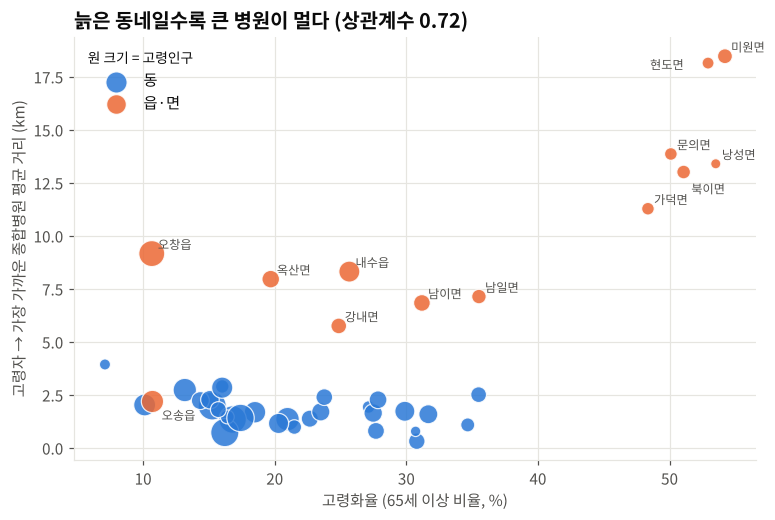

In [4]:
# (1) 행정동별 총인구·65세 이상 인구: 연령별 인구현황 엑셀(구별 시트, 동마다 3열씩)
sheets = pd.read_excel(DATA + '2026년 8월 연령별(만) 인구현황.xlsx', sheet_name=None, engine='calamine', header=None)
num = lambda v: 0 if pd.isna(v) else int(str(v).replace(',', ''))
rows = []
for gu, df in sheets.items():
    if gu == '청주시':
        continue
    lab = df[1].ffill()
    for c in range(6, df.shape[1], 3):          # 3열 = 인구수·구성비·성비, 6열부터 동
        name = df.iat[5, c]
        if pd.isna(name):
            continue
        tot = old = 0
        for i in range(7, len(df)):
            if df.iat[i, 2] != '계':
                continue
            l = str(lab[i]).replace(' ', ''); v = num(df.iat[i, c])
            if l == '합계':
                tot = v
            else:
                m = re.match(r'(\d+)세', l)
                if m and int(m.group(1)) >= 65:
                    old += v
        rows.append((str(name).strip(), tot, old))
pop = pd.DataFrame(rows, columns=['ADM_NM', '총인구', '고령'])
pop['ADM_NM'] = pop.ADM_NM.str.replace('.', '·', regex=False).replace({'강서제1동': '강서1동', '강서제2동': '강서2동', '탑대성동': '탑·대성동'})
pop['고령화율'] = pop['고령'] / pop['총인구'] * 100

# (2) 종합병원 7곳(상급종합 1 + 종합병원 6, 오송 베스티안병원 포함): 의료기관 시트
med = pd.read_excel(DATA + '청주_거점병원_의료접근성_분석.xlsx', sheet_name='청주_의료기관', engine='calamine')
gh = med[med['종별'].isin(['상급종합', '종합병원'])]

# (3) 고령자 위치 대리값: 동 안의 정류장마다 오전 6~9시 승차량 비율로 고령인구를 나눠 배치
am = st[st['시간대'].between(6, 8)].groupby('정류장ID', as_index=False).agg(승차=('승차', 'sum'), 위도=('위도', 'first'), 경도=('경도', 'first'))
am = gpd.sjoin(gpd.GeoDataFrame(am, geometry=gpd.points_from_xy(am.경도, am.위도), crs=4326),
               bnd[['ADM_NM', 'geometry']], how='inner', predicate='within')
am['병원거리'] = np.min([hav_km(am.위도.values, am.경도.values, la, lo) for la, lo in zip(gh['위도(Y)'], gh['경도(X)'])], axis=0) * DETOUR
wdist = am.groupby('ADM_NM').apply(lambda x: np.average(x['병원거리'], weights=x['승차']) if x['승차'].sum() > 0 else x['병원거리'].mean(),
                                   include_groups=False).rename('병원거리')
f1 = pop.merge(wdist, left_on='ADM_NM', right_index=True)
f1['읍면'] = f1.ADM_NM.str[-1].isin(['읍', '면'])
r = np.corrcoef(f1['고령화율'], f1['병원거리'])[0, 1]
print(f'{len(f1)}개 읍면동, 상관계수 r = {r:.2f}')
print(f1.sort_values('병원거리', ascending=False).head(8).round(1).to_string(index=False))
r_ex = None
gh_ex = gh[~gh['요양기관명'].str.contains('베스티안')]
d_ex = np.min([hav_km(am.위도.values, am.경도.values, la, lo) for la, lo in zip(gh_ex['위도(Y)'], gh_ex['경도(X)'])], axis=0) * DETOUR
w_ex = am.assign(d=d_ex).groupby('ADM_NM').apply(lambda x: np.average(x['d'], weights=x['승차']) if x['승차'].sum() > 0 else x['d'].mean(), include_groups=False)
r_ex = np.corrcoef(f1['고령화율'], f1.ADM_NM.map(w_ex))[0, 1]
print(f'참고: 화상 전문 베스티안병원을 빼면 r = {r_ex:.2f}, 오송읍 거리 {w_ex["오송읍"]:.1f}km')

fig, ax = plt.subplots(figsize=(8, 5))
for is_em, col, lab in [(False, C_IN, '동'), (True, C_OUT, '읍·면')]:
    s = f1[f1['읍면'] == is_em]
    ax.scatter(s['고령화율'], s['병원거리'], s=s['고령'] / 25, color=col, alpha=0.85, edgecolor='white', linewidth=0.8, label=lab)
OFF = {'현도면': (-38, -4), '북이면': (5, -14), '오송읍': (6, -12)}   # 겹치는 이름만 위치 조정
for _, rw in f1[f1['읍면']].iterrows():
    ax.annotate(rw.ADM_NM, (rw['고령화율'], rw['병원거리']), xytext=OFF.get(rw.ADM_NM, (4, 3)), textcoords='offset points', fontsize=8, color=INK2)
ax.set_xlabel('고령화율 (65세 이상 비율, %)'); ax.set_ylabel('고령자 → 가장 가까운 종합병원 평균 거리 (km)')
ax.legend(loc='upper left', title='원 크기 = 고령인구', title_fontsize=9)
ax.set_title(f'늙은 동네일수록 큰 병원이 멀다 (상관계수 {r:.2f})')
save(fig, 'fig01_aging_vs_hospital')

## 그림 2. 외곽 12개 읍면 운행의 비중
**데이터**: 해피콜 운행기록(완료 383,964건)의 출발·도착 읍면동, 차량점유(배차→하차), 픽업거리+이동거리

**처리**: 출발 또는 도착이 외곽 12개 읍면이면 "외곽", 동↔동이면 "시내"로 나눠 건수·점유시간·주행거리의 비중과 1건 평균을 비교합니다.

비중(%)
      건수  차량점유(시간)  주행거리(km)
구간                          
외곽  14.8      17.8      26.8
시내  82.9      78.7      68.0
기타   2.3       3.5       5.2

1건 평균
    1건 이동거리(km)  1건 점유(분)  1건 주행(km)
구간                                  
외곽         13.9      35.7       17.3
시내          5.1      28.1        7.8
기타         18.0      44.8       21.6

외곽 1건 이동거리는 시내의 2.7배


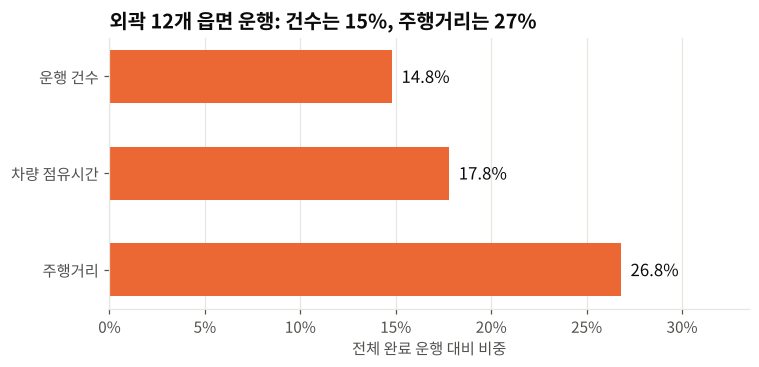

In [5]:
g = done.groupby('구간')
share = pd.DataFrame({
    '건수': g.size(), '차량점유(시간)': g['점유'].sum() / 60, '주행거리(km)': g['주행km'].sum()})
share_pct = (share / share.sum() * 100).round(1)
avg = pd.DataFrame({'1건 이동거리(km)': g['이동거리_km'].mean(), '1건 점유(분)': g['점유'].mean(),
                    '1건 주행(km)': g['주행km'].mean()}).round(1)
print('비중(%)'); print(share_pct.loc[['외곽', '시내', '기타']])
print('\n1건 평균'); print(avg.loc[['외곽', '시내', '기타']])
print(f"\n외곽 1건 이동거리는 시내의 {avg.loc['외곽', '1건 이동거리(km)'] / avg.loc['시내', '1건 이동거리(km)']:.1f}배")

# 그림 1. 외곽 운행이 차지하는 비중
fig, ax = plt.subplots(figsize=(7.5, 3.2))
vals = share_pct.loc['외곽', ['건수', '차량점유(시간)', '주행거리(km)']]
labels = ['운행 건수', '차량 점유시간', '주행거리']
bars = ax.barh(labels[::-1], vals.values[::-1], color=C_OUT, height=0.55)
for b, v in zip(bars, vals.values[::-1]):
    ax.text(v + 0.5, b.get_y() + b.get_height() / 2, f'{v:.1f}%', va='center', color=INK, fontsize=11)
ax.set_xlim(0, max(vals) * 1.25); ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis='y', visible=False)
ax.set_title('외곽 12개 읍면 운행: 건수는 15%, 주행거리는 27%')
ax.set_xlabel('전체 완료 운행 대비 비중')
save(fig, 'fig02_outer_share')

## 그림 3. 외곽 출발 해피콜의 도착 동과 읍면 Hub (지도)
**데이터**: 해피콜 운행기록(외곽 12개 읍면 출발 → 시내 동 도착, 17,910건), 행정동 경계, 읍면 Hub 정류장 좌표, 종합병원 좌표

**처리**: 도착 동별 건수를 세어 동 경계에 색으로 칠하고(진할수록 많음), 외곽 12개 읍면은 베이지, 오송읍은 빗금, Hub는 주황 점, 종합병원은 검은 십자로 표시합니다.

외곽→시내(동) 완료 운행 17,910건 (하루 약 49건), 핵심 목적지 동 비율 63.9%
그중 성화·개신·죽림동(충북대병원) 1,353건
목적지읍면동
율량·사천동       2471
성화·개신·죽림동    1353
가경동          1347
성안동          1328
용암1동         1072
오근장동         1046
영운동           767
운천·신봉동        763
강서1동          739
용암2동          604
Name: count, dtype: int64
참고: 1위 율량·사천동은 보고서의 주요 정류장 권역·종합병원 소재 동이 아니어서 핵심 목적지에서 빠짐 (권역에 포함하면 Hub 대상이 늘어남)


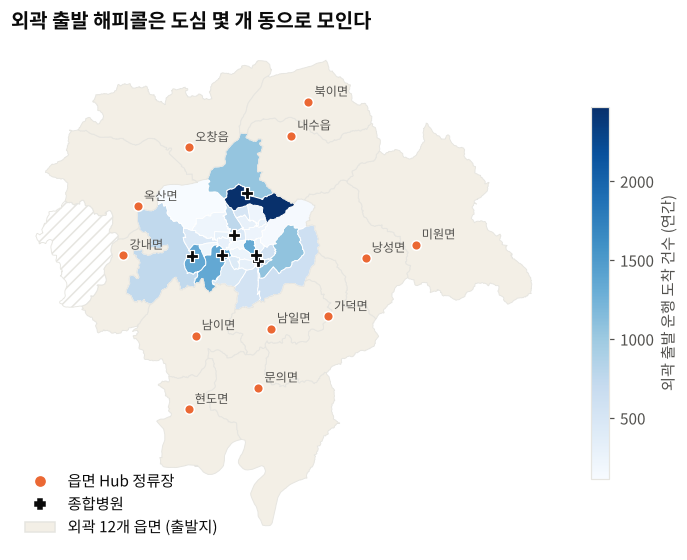

In [6]:
out = done[done.o12 & done.목적지_읍면동구분.eq('동')]
dest = out.목적지읍면동.value_counts()
core_share = out.목적지읍면동.isin(CORE).mean()
print(f'외곽→시내(동) 완료 운행 {len(out):,}건 (하루 약 {len(out) / 365:.0f}건), 핵심 목적지 동 비율 {core_share:.1%}')
print(f"그중 성화·개신·죽림동(충북대병원) {dest.get('성화·개신·죽림동', 0):,}건")
print(dest.head(10))
print('참고: 1위 율량·사천동은 보고서의 주요 정류장 권역·종합병원 소재 동이 아니어서 핵심 목적지에서 빠짐 (권역에 포함하면 Hub 대상이 늘어남)')

# 그림 6. 지도: 외곽 출발 운행의 목적지 동별 건수
m = bnd.merge(dest.rename('건수'), left_on='ADM_NM', right_index=True, how='left').fillna({'건수': 0})
fig, ax = plt.subplots(figsize=(8, 8))
m[m.구분.eq('동')].plot(column='건수', cmap='Blues', ax=ax, edgecolor='white', linewidth=0.6, legend=True,
                       legend_kwds={'label': '외곽 출발 운행 도착 건수 (연간)', 'shrink': 0.55})
m[m.ADM_NM.isin(OUTER12)].plot(ax=ax, color='#f3efe6', edgecolor=GRID, linewidth=0.6)
m[m.ADM_NM.eq('오송읍')].plot(ax=ax, color='white', edgecolor=GRID, linewidth=0.6, hatch='///')
hp = gpd.GeoDataFrame(HUB, geometry=gpd.points_from_xy(HUB.경도, HUB.위도), crs=4326)
hp.plot(ax=ax, color=C_OUT, markersize=40, edgecolor='white', linewidth=1, zorder=3)
hos.plot(ax=ax, color=INK, marker='P', markersize=70, edgecolor='white', linewidth=0.8, zorder=3)
for _, r in hp.iterrows():
    ax.annotate(r.읍면, (r.geometry.x, r.geometry.y), xytext=(4, 4), textcoords='offset points', fontsize=8, color=INK2)
ax.legend(handles=[plt.Line2D([], [], marker='o', ls='', color=C_OUT, label='읍면 Hub 정류장'),
                   plt.Line2D([], [], marker='P', ls='', color=INK, label='종합병원'),
                   Patch(facecolor='#f3efe6', edgecolor=GRID, label='외곽 12개 읍면 (출발지)')], loc='lower left')
ax.set_axis_off(); ax.set_title('외곽 출발 해피콜은 도심 몇 개 동으로 모인다')
save(fig, 'fig03_destination_map')

## 그림 4. 외곽–주요 정류장–충북대병원 저상노선 후보 7개
**데이터**: 정류장 좌표·이용량(승하차 자료), 읍면 Hub 정류장, 주요 정류장 권역 15곳, 행정동 경계, 보고서 7장의 노선표(A~G)

**처리**: 보고서 표의 노선 순서대로 정류장 좌표를 이어 그립니다(정류장 사이를 직선으로 이은 개념도). 원 크기는 권역 대표 정류장의 이용량입니다. 그 아래 셀은 보고서 2장의 노선 설계 규칙(그리디 삽입)을 구현한 참고 코드입니다.

A 32.7km 미원면 → 낭성면 → 가덕면 → 남일면 → 용암효성 → 현대3차 → 분평휴먼시아 → 충북대병원
B 21.7km 북이면 → 내수읍 → 마로니에공원 → 문화제조창 → 청주대 → 도청 → 사직사거리 → 충북대병원
C 18.5km 현도면 → 남이면 → 충북대병원
D 17.3km 문의면 → 분평휴먼시아 → 충북대병원
E 14.2km 오창읍 → 산업단지입구 → 사창사거리 → 충북대병원
F 13.2km 강내면 → 시외버스터미널 → 산업단지입구 → 사창사거리 → 충북대병원
G 13.6km 옥산면 → 시외버스터미널 → 산업단지입구 → 사창사거리 → 충북대병원


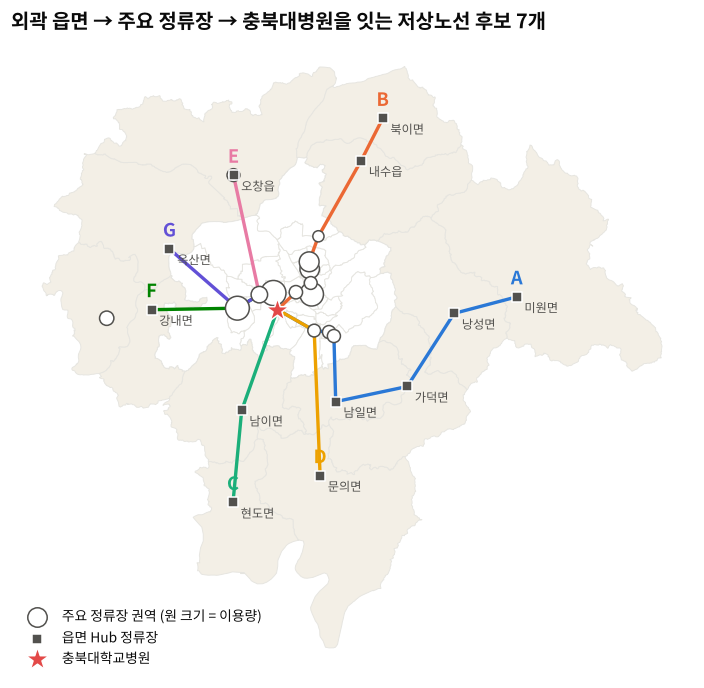

In [7]:
# 노선 그리기에 쓸 점 좌표: 읍면 Hub 정류장, 주요 정류장 권역 대표 정류장, 충북대병원 정류장
name_xy = st.groupby('정류장명').agg(위도=('위도', 'mean'), 경도=('경도', 'mean'), 이용=('승차', 'sum'))
P = {r.읍면: (r.위도, r.경도) for r in HUB.itertuples()}
for k in KW:
    P[k] = tuple(name_xy.loc[k, ['위도', '경도']])
P['충북대병원'] = P['충북대학교병원']
SHORT = {'용암효성': '용암효성아파트', '현대3차': '현대3차아파트', '분평휴먼시아': '분평휴먼시아2단지아파트', '마로니에공원': '마로니에공원',
         '문화제조창': '문화제조창.시청제2임시청사', '청주대': '청주대학교.뉴시스', '도청': '도청.그림책정원1937', '사직사거리': '사직사거리.시립미술관.교육도서관',
         '산업단지입구': '산업단지입구', '사창사거리': '사창사거리', '시외버스터미널': '시외버스터미널'}

# 보고서 7장 표의 최종 노선 7개 (읍면 Hub → 주요 정류장 권역 → 충북대병원)
ROUTES = {
    'A': ['미원면', '낭성면', '가덕면', '남일면', '용암효성', '현대3차', '분평휴먼시아', '충북대병원'],
    'B': ['북이면', '내수읍', '마로니에공원', '문화제조창', '청주대', '도청', '사직사거리', '충북대병원'],
    'C': ['현도면', '남이면', '충북대병원'],
    'D': ['문의면', '분평휴먼시아', '충북대병원'],
    'E': ['오창읍', '산업단지입구', '사창사거리', '충북대병원'],
    'F': ['강내면', '시외버스터미널', '산업단지입구', '사창사거리', '충북대병원'],
    'G': ['옥산면', '시외버스터미널', '산업단지입구', '사창사거리', '충북대병원'],
}
xy = lambda k: P[SHORT.get(k, k)]
def length(seq):
    return sum(hav_km(*xy(a), *xy(b)) for a, b in zip(seq[:-1], seq[1:])) * DETOUR
for k, seq in ROUTES.items():
    print(k, f'{length(seq):.1f}km', ' → '.join(seq))

PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6']
fig, ax = plt.subplots(figsize=(8, 8))
bnd.plot(ax=ax, color=np.where(bnd['구분'] == '읍면', '#f3efe6', '#ffffff'), edgecolor=GRID, linewidth=0.6)
for (k, seq), col in zip(ROUTES.items(), PAL):
    pts = [xy(s) for s in seq]
    ax.plot([p_[1] for p_ in pts], [p_[0] for p_ in pts], color=col, linewidth=2.2, zorder=2)
    ax.text(pts[0][1], pts[0][0] + 0.008, k, color=col, fontsize=12, fontweight='bold', ha='center', zorder=4)
kw_pts = name_xy.loc[[k for k in KW if k not in ('충북대학교병원',)]]
ax.scatter(kw_pts['경도'], kw_pts['위도'], s=kw_pts['이용'] / kw_pts['이용'].max() * 250 + 20, facecolor='white', edgecolor=INK2, linewidth=1, zorder=3, label='주요 정류장 권역 (원 크기 = 이용량)')
ax.scatter(HUB['경도'], HUB['위도'], marker='s', s=40, color=INK2, edgecolor='white', zorder=3, label='읍면 Hub 정류장')
ax.scatter(*P['충북대병원'][::-1], marker='*', s=260, color='#e34948', edgecolor='white', zorder=5, label='충북대학교병원')
for r_ in HUB.itertuples():
    ax.annotate(r_.읍면, (r_.경도, r_.위도), xytext=(5, -10), textcoords='offset points', fontsize=8, color=INK2)
ax.legend(loc='lower left', fontsize=9); ax.set_axis_off()
ax.set_title('외곽 읍면 → 주요 정류장 → 충북대병원을 잇는 저상노선 후보 7개')
save(fig, 'fig04_lowfloor_routes')

In [8]:
# 참고: 보고서 2장에 적힌 노선 설계 규칙(그리디 삽입)을 코드로 구현
# 1) 충북대병원에서 먼 읍면부터 노선을 시작하고, 다른 읍면을 넣어도 노선 길이가 25% 넘게 늘지 않으면 함께 묶는다
# 2) 마지막 읍면 뒤 ~ 병원 앞 구간에, 추가 우회 1.5km 이내로 들를 수 있는 주요 정류장 권역을 이용량 큰 순서로 넣는다
KWSHARE = dict(zip(KW, [14.3, 7.0, 6.4, 3.2, 2.4, 1.8, 1.2, 1.2, 1.2, 1.1, 1.0, 1.0, 1.0, 0.9, 0.7]))   # 보고서 5장 권역 이용 비중(%)
dd = lambda a, b: hav_km(*P[a], *P[b]) * DETOUR
L = lambda r_: sum(dd(a, b) for a, b in zip(r_[:-1], r_[1:]))
order = sorted(HUB['읍면'], key=lambda h: -dd(h, '충북대병원'))
routes, used = [], set()
for h in order:
    if h in used:
        continue
    r_ = [h, '충북대병원']; used.add(h)
    for g_ in order:
        if g_ in used:
            continue
        best = min((r_[:i] + [g_] + r_[i:] for i in range(1, len(r_))), key=L)
        if L(best) <= 1.25 * L(r_):
            r_ = best; used.add(g_)
    routes.append(r_)
cand = [k for k in sorted(KW, key=lambda k: -KWSHARE[k]) if k not in ('충북대학교병원', '오창프라자', '오송역')]
for r_ in routes:
    for k in cand:
        last = max(i for i, x in enumerate(r_) if x in set(HUB['읍면']))
        best = min((r_[:i] + [k] + r_[i:] for i in range(last + 1, len(r_))), key=L)
        if L(best) - L(r_) <= 1.5:
            r_[:] = best
for r_ in routes:
    print(f'{L(r_):.1f}km', ' → '.join(r_))
print('※ 이 규칙만으로는 B·C·E·F·G가 보고서와 같고, A·D는 남일·가덕면 묶음이 달라진다(보고서 노선은 팀의 앞선 단계 코드 결과).')

24.3km 미원면 → 낭성면 → 도청.그림책정원1937 → 시청신청사예정지 → 사직사거리.시립미술관.교육도서관 → 충북대병원
21.7km 북이면 → 내수읍 → 마로니에공원 → 문화제조창.시청제2임시청사 → 청주대학교.뉴시스 → 시청신청사예정지 → 도청.그림책정원1937 → 사직사거리.시립미술관.교육도서관 → 충북대병원
18.5km 현도면 → 남이면 → 충북대병원
18.9km 문의면 → 남일면 → 용암효성아파트 → 현대3차아파트 → 분평휴먼시아2단지아파트 → 충북대병원
14.1km 가덕면 → 용암효성아파트 → 현대3차아파트 → 분평휴먼시아2단지아파트 → 충북대병원
14.2km 오창읍 → 산업단지입구 → 사창사거리 → 충북대병원
13.2km 강내면 → 시외버스터미널 → 산업단지입구 → 사창사거리 → 충북대병원
13.6km 옥산면 → 시외버스터미널 → 산업단지입구 → 사창사거리 → 충북대병원
※ 이 규칙만으로는 B·C·E·F·G가 보고서와 같고, A·D는 남일·가덕면 묶음이 달라진다(보고서 노선은 팀의 앞선 단계 코드 결과).


## 그림 5. 읍면별 운행 1건 차량점유: 현재 vs Hub 연계
**데이터**: 해피콜 완료 운행의 실제 픽업시간·탑승시간·이동거리, 읍면 Hub까지 거리(보고서 3장 표), 핵심 목적지 동

**처리**: 외곽 12개 읍면 ↔ 핵심 목적지 동 운행 중 Hub 거리가 실제 이동거리의 70% 이하인 건을 고르고, 운행마다 `Hub 탑승시간 = 실제 탑승시간 × Hub거리 ÷ 실제 이동거리`로 줄여 차량점유를 다시 계산합니다. 그림은 외곽→시내 방향의 읍면별 평균입니다. 아래 표 계산(시나리오별 연간 절감)도 이 셀에서 합니다.

후보 32,927건 중 70% 규칙 통과 30,125건 (외곽→시내 9,893, 시내→외곽 20,232)
1건당 점유 37.1분 → 15.9분 (21.2분, 57% 절감), 주행 12.3km 절감
     연간건수  현재점유  Hub점유   절감분  특장비율  현행노선연결
읍면                                        
강내면   780  33.5   15.6  17.9   0.3    True
옥산면   965  33.8   14.2  19.6   0.1   False
남일면  1567  34.9   20.5  14.4   0.3   False
내수읍  1619  35.8   17.7  18.1   0.4    True
북이면   286  35.8   14.2  21.6   0.3   False
남이면   513  36.0   23.5  12.6   0.3    True
오창읍  2195  36.3   15.7  20.6   0.2    True
가덕면   176  36.6   17.3  19.3   0.3    True
낭성면   310  38.1   16.3  21.7   0.1    True
문의면   235  41.0   16.4  24.5   0.3    True
현도면    25  44.6   17.6  27.0   0.4   False
미원면  1222  45.0    7.6  37.4   0.0   False
방향   시내→외곽  외곽→시내
읍면               
가덕면    772    212
강내면   1368    829
남이면   2293   1044
남일면   2859   2165
낭성면   1098    351
내수읍   3339   1789
문의면    852    243
미원면   1756   1225
북이면    538    290
오창읍   4802   2277
옥산면   1693    988
현도면    116     28


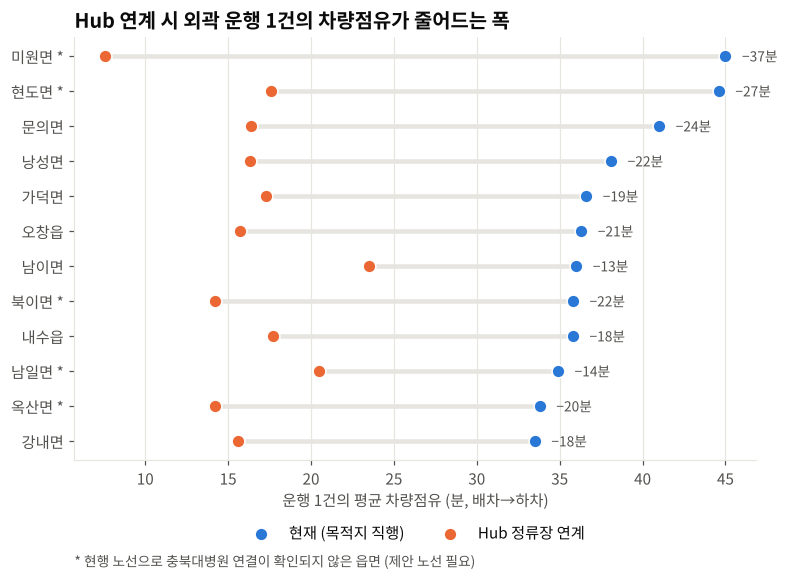

           노선 전환율     차량  대상(건/년)  절감 차량시간(h/년)  추가 처리 가능(건/년)  절감 주행(km/년)
 현행 노선(7개 읍면) 10%    특장차     5574           210            374         5784
 현행 노선(7개 읍면) 10% 그 외 차량    13934           441           1011        15907
 현행 노선(7개 읍면) 30%    특장차     5574           629           1121        17351
 현행 노선(7개 읍면) 30% 그 외 차량    13934          1324           3032        47722
 현행 노선(7개 읍면) 50%    특장차     5574          1048           1868        28918
 현행 노선(7개 읍면) 50% 그 외 차량    13934          2207           5054        79536
제안 노선(12개 읍면) 10%    특장차     7954           300            534         8218
제안 노선(12개 읍면) 10% 그 외 차량    22171           764           1750        28957
제안 노선(12개 읍면) 30%    특장차     7954           899           1601        24654
제안 노선(12개 읍면) 30% 그 외 차량    22171          2293           5250        86872
제안 노선(12개 읍면) 50%    특장차     7954          1498           2669        41091
제안 노선(12개 읍면) 50% 그 외 차량    22171          3821           8750       144786


In [9]:
hubkm = HUB.set_index('읍면')['Hub거리_km']; linked = HUB.set_index('읍면')['현행노선연결']
go = done.o12 & done.목적지읍면동.isin(CORE)
back = done.d12 & done.출발읍면동.isin(CORE)
cand = done[go | back].copy()
cand['방향'] = np.where(go[go | back], '외곽→시내', '시내→외곽')
cand['읍면'] = np.where(cand.방향.eq('외곽→시내'), cand.출발읍면동, cand.목적지읍면동)
cand['Hub거리'] = cand.읍면.map(hubkm)
cand['적용'] = cand.Hub거리 <= 0.7 * cand.이동거리_km
cand['현행연결'] = cand.읍면.map(linked)
el = cand[cand.적용 & cand.탑승시간_분.notna()].copy()
el['Hub탑승'] = el.탑승시간_분 * el.Hub거리 / el.이동거리_km
el['절감분'] = el.탑승시간_분 - el.Hub탑승
el['절감km'] = el.이동거리_km - el.Hub거리
el['Hub점유'] = el.점유 - el.절감분
print(f'후보 {len(cand):,}건 중 70% 규칙 통과 {len(el):,}건 (외곽→시내 {el.방향.eq("외곽→시내").sum():,}, 시내→외곽 {el.방향.eq("시내→외곽").sum():,})')
print(f'1건당 점유 {el.점유.mean():.1f}분 → {el.Hub점유.mean():.1f}분 ({el.절감분.mean():.1f}분, {el.절감분.sum() / el.점유.sum():.0%} 절감), 주행 {el.절감km.mean():.1f}km 절감')

per = el[el.방향.eq('외곽→시내')].groupby('읍면').agg(
    연간건수=('운행ID', 'size'), 현재점유=('점유', 'mean'), Hub점유=('Hub점유', 'mean'),
    절감분=('절감분', 'mean'), 특장비율=('특장', 'mean')).round(1).sort_values('현재점유')
per['현행노선연결'] = per.index.map(linked)
print(per)
# 관찰: 모든 읍면에서 시내→외곽 운행이 외곽→시내의 약 2배다. 시내→외곽 호출은 10~11시, 15시에 몰려 병원 진료 뒤 귀가로 보인다.
# (가는 길은 가족 차량·예약 등 다른 수단을 쓰고 귀가할 때 해피콜을 부르는 경우가 많을 수 있음 → 공단 확인 권장)
print(pd.crosstab(cand.읍면, cand.방향))

# 그림 7. 읍면별 1건 차량점유: 현재 vs Hub 연계 (외곽→시내)
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(per))
ax.hlines(y, per.Hub점유, per.현재점유, color=GRID, linewidth=3, zorder=1)
ax.scatter(per.현재점유, y, color=C_IN, s=70, zorder=2, label='현재 (목적지 직행)', edgecolor='white', linewidth=1)
ax.scatter(per.Hub점유, y, color=C_OUT, s=70, zorder=2, label='Hub 정류장 연계', edgecolor='white', linewidth=1)
for i, (k, r) in enumerate(per.iterrows()):
    ax.text(r.현재점유 + 1, i, f'−{r.절감분:.0f}분', va='center', fontsize=9, color=INK2)
ax.set_yticks(y, [f'{k}{"" if per.loc[k, "현행노선연결"] else " *"}' for k in per.index])
ax.set_xlabel('운행 1건의 평균 차량점유 (분, 배차→하차)'); ax.grid(axis='y', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_title('Hub 연계 시 외곽 운행 1건의 차량점유가 줄어드는 폭')
ax.text(0, -0.25, '* 현행 노선으로 충북대병원 연결이 확인되지 않은 읍면 (제안 노선 필요)', transform=ax.transAxes, fontsize=9, color=INK2)
save(fig, 'fig05_hub_occupancy')

# 시나리오별 연간 효과
rows = []
avg_occ_sp = done.loc[done.특장, '점유'].mean(); avg_occ_ns = done.loc[~done.특장, '점유'].mean()
for net, sel in [('현행 노선(7개 읍면)', el.현행연결), ('제안 노선(12개 읍면)', pd.Series(True, index=el.index))]:
    e = el[sel]
    for rate in [0.1, 0.3, 0.5]:
        for grp, mask, occ in [('특장차', e.특장, avg_occ_sp), ('그 외 차량', ~e.특장, avg_occ_ns)]:
            h = e.loc[mask, '절감분'].sum() * rate / 60
            rows.append({'노선': net, '전환율': f'{rate:.0%}', '차량': grp, '대상(건/년)': int(mask.sum()),
                         '절감 차량시간(h/년)': round(h), '추가 처리 가능(건/년)': round(h * 60 / occ),
                         '절감 주행(km/년)': round(e.loc[mask, '절감km'].sum() * rate)})
sc = pd.DataFrame(rows)
print(sc.to_string(index=False))

## 그림 6. 평일 시간대별 동시 운행 특장차
**데이터**: 해피콜 완료 운행 중 특장차의 배차 시각과 차량점유 시간(예약 운행은 승차 시각에서 픽업 중앙값만큼 앞당김)

**처리**: 운행마다 [배차, 하차] 구간을 1분 단위 배열에 +1/−1로 쌓아 누적합을 구하면 그 분에 운행 중인 특장차 수가 됩니다. 평일만 골라 시각별 평균을 외곽·그 외로 나눠 쌓습니다.

평일 특장차 동시 운행 최대 37.5대 (9시), 그중 외곽 3.7대
평일 07~19시 외곽 운행이 묶은 특장차 평균 2.8대


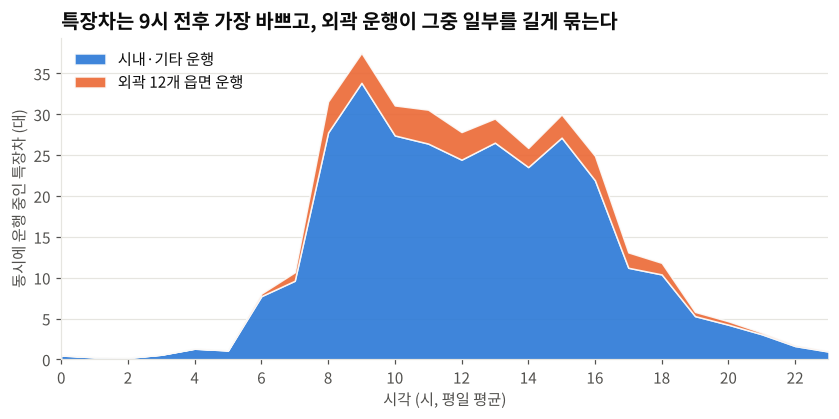

In [10]:
# 특장차 동시 운행 대수 (1분 해상도) – 평일 시간대별 평균
sp = done[done.특장].copy()
start = sp['일자'] + pd.to_timedelta(sp['배차시간'])
# 예약 운행은 승차 시각에서 픽업 중앙값만큼 앞당겨 시작으로 봄
start = np.where(sp.예약일반.eq('일반'), start,
                 sp['일자'] + pd.to_timedelta(sp['승차시간']) - pd.to_timedelta(sp['픽업'], unit='m'))
sp['t0'] = pd.to_datetime(start); sp['t1'] = sp['t0'] + pd.to_timedelta(sp['점유'], unit='m')
sp = sp.dropna(subset=['t0', 't1'])
T0 = hc['일자'].min(); n_min = int((hc['일자'].max() + pd.Timedelta(days=2) - T0) / pd.Timedelta(minutes=1))
def busy(df):
    a = ((df.t0 - T0) / pd.Timedelta(minutes=1)).astype(int).clip(0, n_min - 1).values
    b = ((df.t1 - T0) / pd.Timedelta(minutes=1)).astype(int).clip(0, n_min - 1).values
    arr = np.zeros(n_min + 1); np.add.at(arr, a, 1); np.add.at(arr, b, -1)
    return np.cumsum(arr)[:n_min]
idx = T0 + pd.to_timedelta(np.arange(n_min), unit='m')
prof = pd.DataFrame({'외곽': busy(sp[sp.구간.eq('외곽')]), '그 외': busy(sp[~sp.구간.eq('외곽')])}, index=idx)
prof = prof[(prof.index.dayofweek < 5) & (prof.index < hc['일자'].max() + pd.Timedelta(days=1))]
hourly = prof.groupby(prof.index.hour).mean()
peak_h = hourly.sum(axis=1).idxmax()
print(f'평일 특장차 동시 운행 최대 {hourly.sum(axis=1).max():.1f}대 ({peak_h}시), 그중 외곽 {hourly.loc[peak_h, "외곽"]:.1f}대')
print(f'평일 07~19시 외곽 운행이 묶은 특장차 평균 {hourly.loc[7:18, "외곽"].mean():.1f}대')

fig, ax = plt.subplots(figsize=(9, 3.8))
x = hourly.index
ax.stackplot(x, hourly['그 외'], hourly['외곽'], colors=[C_IN, C_OUT], alpha=0.9,
             labels=['시내·기타 운행', '외곽 12개 읍면 운행'], edgecolor='#fcfcfb', linewidth=1)
ax.set_xticks(range(0, 24, 2)); ax.set_xlim(0, 23)
ax.set_xlabel('시각 (시, 평일 평균)'); ax.set_ylabel('동시에 운행 중인 특장차 (대)')
ax.legend(loc='upper left'); ax.grid(axis='x', visible=False)
ax.set_title(f'특장차는 {peak_h}시 전후 가장 바쁘고, 외곽 운행이 그중 일부를 길게 묶는다')
save(fig, 'fig06_wheelchair_busy')

## 그림 7. 실측 재생 시뮬레이션
**데이터**: 특장차 일반 호출 완료 운행 174,731건의 실제 접수 시각·픽업시간·탑승시간, 그림 5의 Hub 연계 탑승시간, 그림 6의 시간대별 동시 운행 대수(강건성 확인용)

**처리**: 1년치 호출을 접수 순서대로 흘려보내 가장 먼저 비는 차량을 배정합니다(대기 = 차량이 빌 때까지 + 실제 픽업시간). 차량 수 N을 바꿔 실측 평균 대기 20.1분에 가장 가까운 N(35대)을 고르고, 같은 N에서 Hub 연계 운행만 탑승시간을 줄여 다시 돌립니다. 왼쪽은 실측·시뮬레이션 대기 분포, 오른쪽은 차량 수별 평균 대기입니다. 실행에 1~2분 걸립니다.

실측 평균 대기 20.1분 → 보정 특장차 대수 N=35 (시뮬레이션 21.1분, 2단계 평일 최대 동시 운행 38대)


       시나리오  평균 대기(분)  95% 대기(분)  07~19시 평균(분) 평균 대기 변화
         현행      21.1       50.0          21.7      +0%
 Hub 연계 30%      20.3       47.5          20.8      -4%
 Hub 연계 50%      19.8       45.9          20.3      -6%
Hub 연계 100%      18.8       42.3          19.1     -11%
Hub 연계 대상은 특장차 일반 호출의 4.5% (7,939건)


[강건성] 시간대별 차량 모형(f=1.15): 현행 20.8분 → 전환 50% 19.7분 (-5%)
특장차 전체 하루 운행 270시간 중 전환 50% 절감 하루 4.1시간 (1.5%)


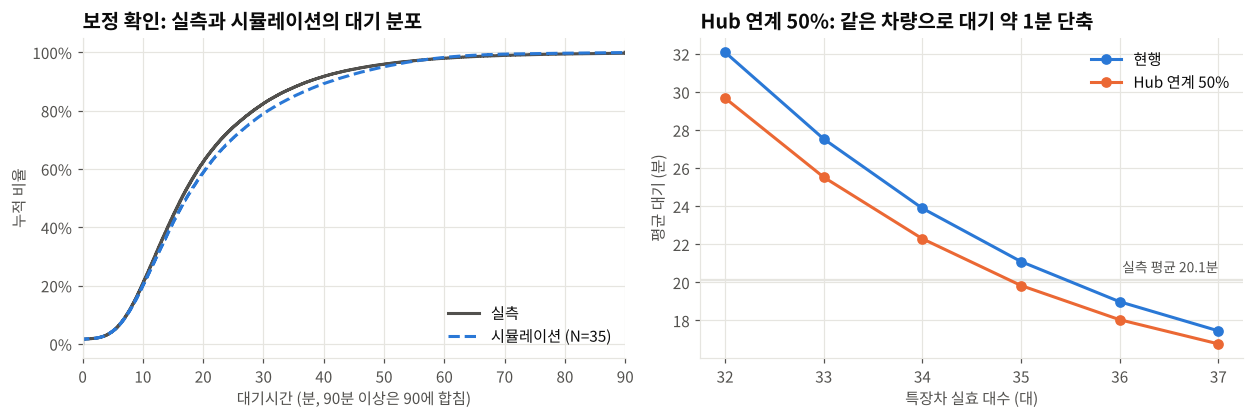

In [11]:
sim = done[done.특장 & done.예약일반.eq('일반')].copy()
sim['t'] = ((sim['일자'] + pd.to_timedelta(sim['접수시간']) - T0) / pd.Timedelta(minutes=1)).values
sim = sim.dropna(subset=['픽업소요_분', '탑승시간_분']).sort_values('t').reset_index(drop=True)
obs_wait = sim['대기시간_분'].mean()
tt = T0 + pd.to_timedelta(sim['t'], unit='m')
sim_we, sim_h = (tt.dt.dayofweek >= 5).values, tt.dt.hour.values

def run(fa, fmax, ride):
    """fa: 호출마다 근무 중인 차량 수, fmax: 최대 차량 수"""
    t = sim['t'].values; pk = sim['픽업소요_분'].values
    free = np.zeros(fmax); w = np.empty(len(t))
    for i in range(len(t)):
        j = np.argmin(free[:fa[i]]); s = max(t[i], free[j])
        w[i] = s - t[i] + pk[i]; free[j] = s + pk[i] + ride[i]
    return w
def run_const(n, ride):
    return run(np.full(len(sim), n), n, ride)

base_ride = sim['탑승시간_분'].values
calib = {n: run_const(n, base_ride) for n in range(31, 40)}
N = min(calib, key=lambda n: abs(calib[n].mean() - obs_wait))
print(f'실측 평균 대기 {obs_wait:.1f}분 → 보정 특장차 대수 N={N} (시뮬레이션 {calib[N].mean():.1f}분, 2단계 평일 최대 동시 운행 {hourly.sum(axis=1).max():.0f}대)')

hub_ride = el[el.특장 & el.예약일반.eq('일반')].set_index('운행ID')['Hub탑승']
is_el = sim['운행ID'].isin(hub_ride.index).values
ride_hub = base_ride.copy(); ride_hub[is_el] = hub_ride.loc[sim.loc[is_el, '운행ID']].values
rng = np.random.default_rng(42); u = rng.random(len(sim))
def ride_rate(rate):
    r = base_ride.copy(); m = is_el & (u < rate); r[m] = ride_hub[m]; return r

pk_mask = (sim_h >= 7) & (sim_h <= 18)
rows = []
for lab, rate in [('현행', 0), ('Hub 연계 30%', 0.3), ('Hub 연계 50%', 0.5), ('Hub 연계 100%', 1.0)]:
    w = calib[N] if rate == 0 else run_const(N, ride_rate(rate))
    rows.append({'시나리오': lab, '평균 대기(분)': round(w.mean(), 1), '95% 대기(분)': round(np.percentile(w, 95), 1),
                 '07~19시 평균(분)': round(w[pk_mask].mean(), 1)})
simres = pd.DataFrame(rows)
simres['평균 대기 변화'] = (simres['평균 대기(분)'] / simres['평균 대기(분)'].iloc[0] - 1).map('{:+.0%}'.format)
print(simres.to_string(index=False))
print(f'Hub 연계 대상은 특장차 일반 호출의 {is_el.mean():.1%} ({is_el.sum():,}건)')

# 강건성: 시간대별 근무 차량 수 = 2단계 동시 운행 대수(평일/주말×시각) × 배율 f
allb = busy(sp)
dts = T0 + pd.to_timedelta(np.arange(n_min), unit='m')
busy_prof = pd.Series(allb).groupby([dts.dayofweek >= 5, dts.hour]).mean()
def fleet(f):
    F = np.maximum(1, np.ceil(busy_prof.values * f)).astype(int); m = dict(zip(busy_prof.index, F))
    return np.array([m[(w_, h_)] for w_, h_ in zip(sim_we, sim_h)]), F.max()
fres = {f: run(*fleet(f), base_ride).mean() for f in [1.10, 1.15, 1.20]}
fb = min(fres, key=lambda f: abs(fres[f] - obs_wait))
h0, h50 = fres[fb], run(*fleet(fb), ride_rate(0.5)).mean()
print(f'[강건성] 시간대별 차량 모형(f={fb}): 현행 {h0:.1f}분 → 전환 50% {h50:.1f}분 ({h50 / h0 - 1:+.0%})')

op_h = done[done.특장].groupby('일자')['점유'].sum().mean() / 60
saved50 = sc.query("노선.str.startswith('제안') and 전환율 == '50%' and 차량 == '특장차'", engine='python')['절감 차량시간(h/년)'].iloc[0]
print(f'특장차 전체 하루 운행 {op_h:,.0f}시간 중 전환 50% 절감 하루 {saved50 / 365:.1f}시간 ({saved50 / 365 / op_h:.1%})')

# 그림 9
curve = pd.DataFrame({'현행': {n: calib[n].mean() for n in range(N - 3, N + 3)},
                      'Hub 연계 50%': {n: run_const(n, ride_rate(0.5)).mean() for n in range(N - 3, N + 3)}})
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
ax = axes[0]
for lab, x, col, ls in [('실측', sim['대기시간_분'].values, INK2, '-'), (f'시뮬레이션 (N={N})', calib[N], C_IN, '--')]:
    xs = np.sort(np.clip(x, 0, 90)); ax.plot(xs, np.arange(1, len(xs) + 1) / len(xs), color=col, linewidth=2, linestyle=ls, label=lab)
ax.set_xlim(0, 90); ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set_xlabel('대기시간 (분, 90분 이상은 90에 합침)'); ax.set_ylabel('누적 비율')
ax.legend(loc='lower right'); ax.set_title('보정 확인: 실측과 시뮬레이션의 대기 분포')
ax = axes[1]
for lab, col in [('현행', C_IN), ('Hub 연계 50%', C_OUT)]:
    ax.plot(curve.index, curve[lab], marker='o', color=col, linewidth=2, label=lab)
ax.axhline(obs_wait, color=GRID, linewidth=1.5, zorder=0)
ax.text(curve.index.max(), obs_wait + 0.4, f'실측 평균 {obs_wait:.1f}분', fontsize=9, color=INK2, ha='right')
ax.set_xticks(curve.index); ax.set_xlabel('특장차 실효 대수 (대)'); ax.set_ylabel('평균 대기 (분)'); ax.legend(loc='upper right')
ax.set_title('Hub 연계 50%: 같은 차량으로 대기 약 1분 단축')
fig.tight_layout()
save(fig, 'fig07_simulation')

## 그림 8. 외곽 출발 해피콜의 도착 동 상위 12곳
**데이터**: 그림 3과 같은 외곽→시내 운행 17,910건, 핵심 목적지 동 목록

**처리**: 도착 동별 건수 상위 12곳을 막대로 그리고, 핵심 목적지 동은 주황, 그 외는 회색으로 칠합니다.

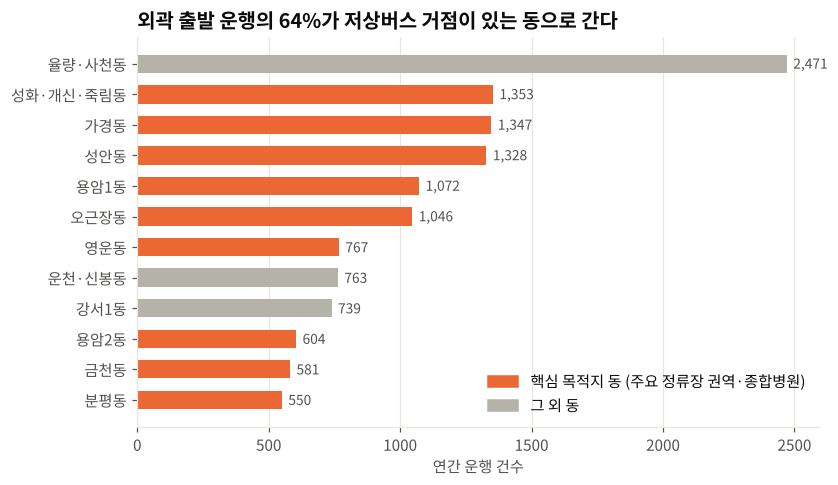

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.6))
top = dest.head(12)[::-1]
cols = [C_OUT if d in CORE else C_GRAY for d in top.index]
bars = ax.barh(top.index, top.values, color=cols, height=0.6)
for b, v in zip(bars, top.values):
    ax.text(v + top.max() * 0.01, b.get_y() + b.get_height() / 2, f'{v:,}', va='center', fontsize=9, color=INK2)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C_OUT, label='핵심 목적지 동 (주요 정류장 권역·종합병원)'), Patch(color=C_GRAY, label='그 외 동')],
          loc='lower right')
ax.set_xlabel('연간 운행 건수'); ax.grid(axis='y', visible=False)
ax.set_title(f'외곽 출발 운행의 {core_share:.0%}가 저상버스 거점이 있는 동으로 간다')
save(fig, 'fig08_outer_destinations')

## 그림 9. 운행 1건 이동거리 분포: 외곽 vs 시내
**데이터**: 해피콜 완료 운행의 이동거리(km)

**처리**: 외곽·시내 운행의 이동거리를 1km 간격 히스토그램(비율)으로 겹쳐 그리고, 범례에 중앙값을 적습니다.

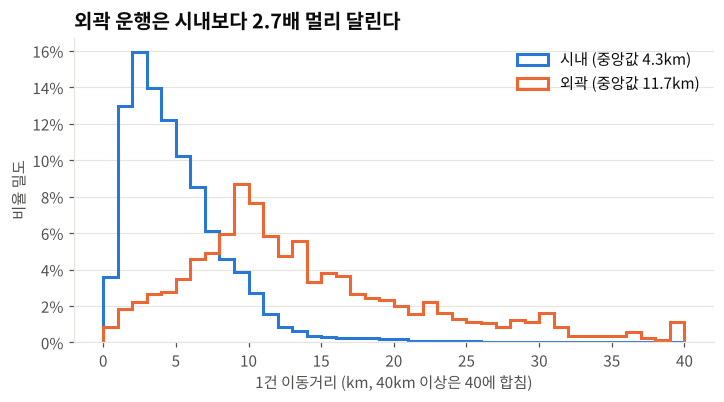

In [13]:
# 그림 2. 1건 이동거리 분포 (외곽 vs 시내)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.arange(0, 40.5, 1)
for k, col in [('시내', C_IN), ('외곽', C_OUT)]:
    x = done.loc[done.구간.eq(k), '이동거리_km'].clip(upper=40)
    ax.hist(x, bins=bins, density=True, histtype='step', linewidth=2, color=col,
            label=f'{k} (중앙값 {x.median():.1f}km)')
ax.set_xlabel('1건 이동거리 (km, 40km 이상은 40에 합침)'); ax.set_ylabel('비율 밀도')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.legend(loc='upper right'); ax.grid(axis='x', visible=False)
ax.set_title('외곽 운행은 시내보다 2.7배 멀리 달린다')
save(fig, 'fig09_trip_distance')

## 그림 10. 차종별 평균 대기와 접수 시각별 취소율
**데이터**: 대기 = 완료된 일반 호출의 접수→승차 시간, 취소율 = 전체 호출(취소·고객없음 포함)

**처리**: 특장차와 그 외 차량의 평균 대기를 막대로, 접수 시각(0~23시)별 취소 비율을 선으로 그립니다. 16~19시를 강조합니다.

        mean  median    size
차종                          
자가용승용차  29.6    29.2    4736
임차택시    21.9    18.8    8083
특장차     20.1    16.4  174747
바우처택시   13.8    10.8  195713
전체 17.1분 / 특장차 20.1분 / 그 외 14.5분 → 39% 김
16~19시 취소율 20.8% (2026년만 19.7%)


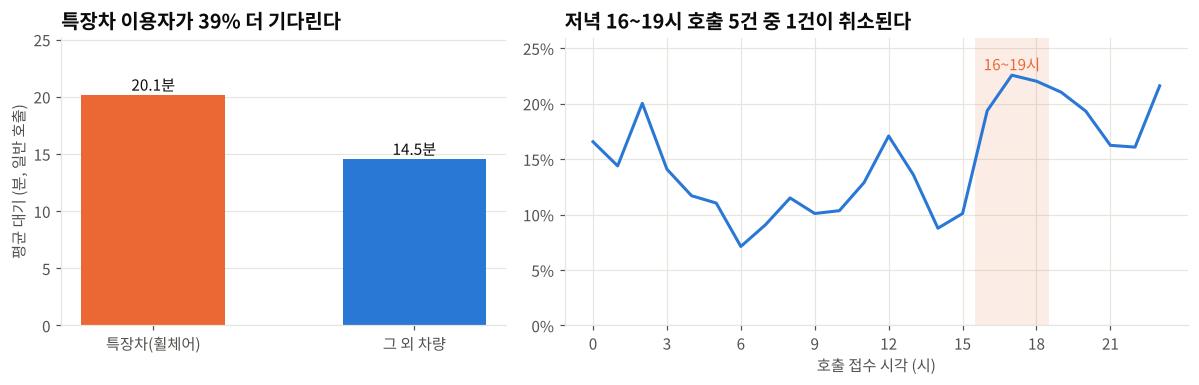

In [14]:
# 차종별 대기(일반 호출) / 접수 시각별 취소율(전체 호출)
nd = done[done.예약일반.eq('일반')]
wait = nd.groupby('차종')['대기시간_분'].agg(['mean', 'median', 'size']).round(1).sort_values('mean', ascending=False)
print(wait)
wt_sp = nd.loc[nd.특장, '대기시간_분'].mean(); wt_ns = nd.loc[~nd.특장, '대기시간_분'].mean()
print(f'전체 {nd.대기시간_분.mean():.1f}분 / 특장차 {wt_sp:.1f}분 / 그 외 {wt_ns:.1f}분 → {wt_sp / wt_ns - 1:.0%} 김')
cancel_h = hc.groupby('접수시')['취소'].mean() * 100
print(f"16~19시 취소율 {hc[hc.접수시.between(16, 18)].취소.mean():.1%} (2026년만 {hc[y26 & hc.접수시.between(16, 18)].취소.mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={'width_ratios': [1, 1.4]})
ax = axes[0]
w = pd.Series({'특장차(휠체어)': wt_sp, '그 외 차량': wt_ns})
bars = ax.bar(w.index, w.values, color=[C_OUT, C_IN], width=0.55)
for b, v in zip(bars, w.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.4, f'{v:.1f}분', ha='center', color=INK)
ax.set_ylim(0, w.max() * 1.25); ax.set_ylabel('평균 대기 (분, 일반 호출)'); ax.grid(axis='x', visible=False)
ax.set_title('특장차 이용자가 39% 더 기다린다')
ax = axes[1]
ax.plot(cancel_h.index, cancel_h.values, color=C_IN, linewidth=2)
ax.axvspan(15.5, 18.5, color=C_OUT, alpha=0.12, linewidth=0)
ax.text(17, cancel_h.max() * 1.02, '16~19시', ha='center', color=C_OUT, fontsize=10)
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel('호출 접수 시각 (시)')
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0)); ax.set_ylim(0, cancel_h.max() * 1.15)
ax.set_title('저녁 16~19시 호출 5건 중 1건이 취소된다')
fig.tight_layout()
save(fig, 'fig10_wait_cancel')